In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns

In [19]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import urllib.request

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
urllib.request.urlretrieve(url, "data-week-HW3.csv")

import pandas as pd
df = pd.read_csv("data-week-HW3.csv")


In [4]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:
df.dtypes

lead_source                  object
industry                     object
employment_status            object
location                     object
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [6]:
df.shape

(5000, 9)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [8]:
df.describe()

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,4631.000000,5000.000000,5000.000000,4965.000000,5000.000000
mean,54533.212049,2.089400,4.472600,0.494767,0.576600
std,21245.661710,1.188987,2.435906,0.199431,0.494147
min,12000.000000,0.000000,0.000000,0.010000,0.000000
25%,40458.500000,1.000000,3.000000,0.360000,0.000000
50%,55051.000000,2.000000,4.000000,0.490000,1.000000
75%,71252.500000,3.000000,6.000000,0.630000,1.000000
max,109886.000000,6.000000,13.000000,0.990000,1.000000


In [9]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [10]:
(df.isna().mean() * 100).round(2)

lead_source                 2.96
industry                    4.80
employment_status           3.88
location                    4.16
annual_income               7.38
number_of_courses_viewed    0.00
interaction_count           0.00
lead_score                  0.70
converted                   0.00
dtype: float64

In [11]:
df["industry"].value_counts().idxmax()

'technology'

In [14]:
df_clean = df.copy()

# Kategorien → häufigster Wert (Modus)
cat_cols = ["lead_source", "industry", "employment_status", "location"]
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# Zahlen → Median
num_cols = ["annual_income", "lead_score"]
for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Prüfen: alles 0
df_clean.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [16]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [17]:
corr = df_clean.select_dtypes(include=[np.number]).corr()
corr

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
annual_income,1.000000,0.131421,0.101916,0.220129,0.173699
number_of_courses_viewed,0.131421,1.000000,0.721609,0.767484,0.395038
interaction_count,0.101916,0.721609,1.000000,0.926248,0.448624
lead_score,0.220129,0.767484,0.926248,1.000000,0.488376
converted,0.173699,0.395038,0.448624,0.488376,1.000000


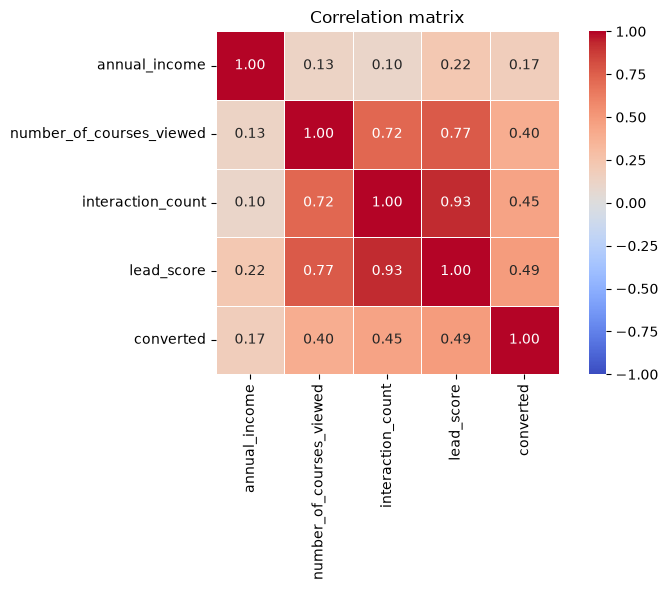

In [21]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,      # Zahlen in den Kästchen
    fmt=".2f",       # 2 Nachkommastellen
    cmap="coolwarm", # rot-blau
    vmin=-1, vmax=1, # Korrelation von -1 bis 1
    square=True,
    linewidths=0.5,
)

plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

In [26]:
from sklearn.metrics import mutual_info_score
from sklearn.model_selection import train_test_split

In [28]:
y = df_clean["converted"].values
df_train, df_val, y_train, y_val = train_test_split(
    df_clean, y, test_size=0.2, random_state=42
)


In [29]:
categorical = ["lead_source", "industry", "employment_status", "location"]

In [30]:
def mi_with_target(series):
    return mutual_info_score(series, y_train)

In [31]:
mi = df_train[categorical].apply(mi_with_target)
mi = mi.round(2).sort_values(ascending=False)
print(mi)
print("\nBiggest MI:", mi.idxmax())

lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
dtype: float64

Biggest MI: lead_source


In [47]:
del df_clean["converted"] 

In [48]:
df_train, df_temp, y_train, y_temp = train_test_split(
    df_clean, y, test_size=0.4, random_state=42
)
df_val, df_test, y_val, y_test = train_test_split(
    df_temp, y_temp, test_size=0.5, random_state=42
)

In [49]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [50]:
dv = DictVectorizer(sparse=False)

In [51]:
X_train = dv.fit_transform(df_train.to_dict(orient="records"))
X_val = dv.transform(df_val.to_dict(orient="records"))

In [56]:
model = LogisticRegression(
    solver="liblinear", C=0.001, max_iter=1000, random_state=42
)
model.fit(X_train, y_train)
y_pred = model.predict(X_val)
accuracy = round((y_pred == y_val).mean(), 2)
print("Validation accuracy:", accuracy)

Validation accuracy: 0.67
